# Milestone 1: data, text embeddings, and first samples

This notebook prepares COCO 2017 val, encodes every caption with the CLIP ViT-L/14 text encoder that Stable Diffusion 1.5 reads, checks that the embeddings are meaningful, and generates the first samples **from the cached embeddings**, not from raw text. That last point matters: it proves the text-to-embedding pipeline we built is the one driving the image.

In [1]:
import sys, json, random, time, textwrap
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from w2w import data, encode, retrieval, generate
from w2w.paths import RESULTS

OUT = RESULTS / "m1_pipeline"
OUT.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0); random.seed(0); np.random.seed(0)
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 NVIDIA GeForce RTX 5070 Laptop GPU


## 1. Download and clean
Cleaning is light and logged: whitespace fixes, duplicate captions dropped, wording never changed. Images are kept; grayscale ones are converted at load time.

In [2]:
data.download()
enc = encode.TextEncoder()
df = data.build_manifest(tokenizer=enc.tokenizer)
log = json.load(open(data.CLEANING_LOG))
print(json.dumps(log, indent=2))
df.head()

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

{
  "captions_over_token_limit": 0,
  "images_short_side_under_256": 42,
  "captions_whitespace_fixed": 3832,
  "captions_duplicate_dropped": 10,
  "images_not_rgb": 10,
  "images_total": 5000,
  "captions_total": 25004
}


,image_id,file_name,width,height,mode,n_captions_raw,captions,n_captions,captions_over_limit,categories
0,139,000000000139.jpg,640,426,RGB,5,[A woman stands in the dining area at the tabl...,5,0,"[book, chair, clock, dining table, microwave, ..."
1,285,000000000285.jpg,586,640,RGB,5,[A big burly grizzly bear is show with grass i...,5,0,[bear]
2,632,000000000632.jpg,640,483,RGB,5,"[Bedroom scene with a bookcase, blue comforter...",5,0,"[bed, book, chair, potted plant]"
3,724,000000000724.jpg,375,500,RGB,5,[A stop sign is mounted upside-down on it's po...,5,0,"[car, stop sign, truck]"
4,776,000000000776.jpg,428,640,RGB,5,"[Three teddy bears, each a different color, sn...",5,0,"[bed, teddy bear]"


## 2. What the captions look like

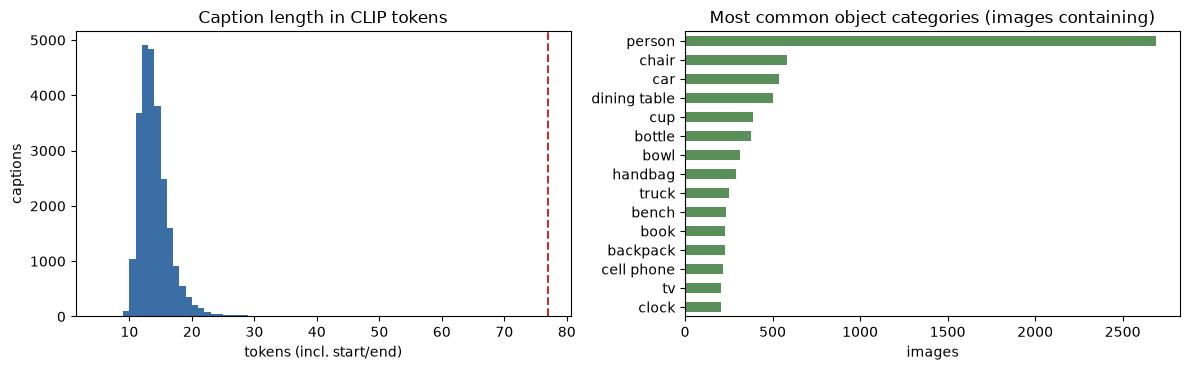

25,004 captions, median 13 tokens, max 58; 0 exceed the 77-token window


In [3]:
caps = data.caption_table(df)
lengths = np.array([len(enc.tokenizer(c)["input_ids"]) for c in caps.caption])
cat_counts = pd.Series([c for cs in df.categories for c in cs]).value_counts()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(lengths, bins=range(5, 60), color="#3b6ea5")
ax[0].axvline(77, color="#b33", ls="--")
ax[0].set(title="Caption length in CLIP tokens", xlabel="tokens (incl. start/end)", ylabel="captions")
cat_counts.head(15)[::-1].plot.barh(ax=ax[1], color="#5a8f5a")
ax[1].set(title="Most common object categories (images containing)", xlabel="images")
plt.tight_layout(); plt.savefig(OUT / "caption_stats.png", dpi=150); plt.show()
print(f"{len(caps):,} captions, median {int(np.median(lengths))} tokens, max {lengths.max()}; "
      f"{(lengths > 77).sum()} exceed the 77-token window")

## 3. Encode every caption and cache it
Two outputs per caption: the 77 x 768 token states the UNet cross-attends to, and CLIP's pooled sentence vector for retrieval and scoring. Plus the empty-prompt states that classifier-free guidance runs against.

In [4]:
t0 = time.perf_counter()
# batch=1 on purpose: Stable Diffusion encodes one prompt at a time, and fp16 matrix math on the GPU
# gives slightly different numbers at larger batch sizes. Encoding one at a time makes the cache
# bit-identical to what the pipeline computes (checked in section 5).
paths = encode.build_cache(enc, caps.caption.tolist(), batch=1)
cache = encode.load_cache()
assert cache["states"].shape == (len(caps), 77, 768), "cache does not line up with the caption table"
print(f"encoded {len(caps):,} captions in {time.perf_counter() - t0:.1f} s")
print({k: v.shape for k, v in cache.items()})
caps.to_parquet(data.COCO / "captions.parquet", index=False)

encoded 25,004 captions in 417.4 s
{'states': (25004, 77, 768), 'pooled': (25004, 768), 'mask': (25004, 77), 'null': (77, 768)}


## 4. Retrieval check: do the embeddings mean anything?
For every caption, rank all 5,000 images by CLIP similarity. Chance recall@1 is 1 in 5,000.

In [5]:
img_emb = retrieval.image_embeddings(enc, df.file_name.tolist())
row_of = {iid: i for i, iid in enumerate(df.image_id)}
caption_row = caps.image_id.map(row_of).to_numpy()
rec = retrieval.recall_at_k(cache["pooled"], img_emb, caption_row)
rec["chance_recall@1"] = 1 / len(df)
np.save(encode.CACHE / "coco_val_image_emb.npy", img_emb.astype(np.float16))
print(json.dumps(rec, indent=2))

# free the CLIP model before loading Stable Diffusion; 8 GB is shared with the desktop
del enc.model
torch.cuda.empty_cache()

{
  "recall@1": 0.35494320908654614,
  "recall@5": 0.5993840985442329,
  "recall@10": 0.7027675571908495,
  "median_rank": 3.0,
  "n_captions": 25004,
  "n_images": 5000,
  "chance_recall@1": 0.0002
}


## 5. Parity check against Stable Diffusion's own text encoder
Our cached states must match what the pipeline would compute from the raw text, or every later experiment is built on sand. A first run that encoded the cache in batches of 256 failed the image check (mean pixel difference 3.48): GPU half-precision math varies slightly with batch size, and 30 denoising steps amplify it. Encoding one caption at a time removes the difference.

In [6]:
pipe = generate.load_pipeline()

# (a) token states: first 8 captions, the longest caption (truncated at 77), and the empty prompt
longest = int(np.argmax(lengths))
probe_idx = list(range(8)) + [longest]
probe = caps.caption.iloc[probe_idx].tolist() + [""]
# one prompt at a time, exactly as the pipeline encodes a prompt (see the note on batch size above)
refs = []
with torch.no_grad():
    for text in probe:
        tok = pipe.tokenizer([text], padding="max_length", max_length=77, truncation=True, return_tensors="pt")
        refs.append(pipe.text_encoder(tok.input_ids.to("cuda"))[0].float().cpu().numpy())
ref = np.concatenate(refs)
ours = np.concatenate([np.asarray(cache["states"][probe_idx], dtype=np.float32),
                       np.asarray(cache["null"], dtype=np.float32)[None]])
diff = float(np.abs(ref - ours).max())
mean_diff = float(np.abs(ref - ours).mean())
print(f"token states: max abs diff {diff:.4g}, mean abs diff {mean_diff:.3g}")
# fp16 spacing is about 0.03 near the largest values (~33), so compare with a tolerance, not exact equality
assert np.allclose(ref, ours, rtol=1e-2, atol=5e-2), "cached states do not match the pipeline's text encoder"

# (b) end to end: the same caption and seed through pipe(prompt=...) and through our cached states
cap0 = caps.caption.iloc[0]
g = torch.Generator("cuda").manual_seed(123)
img_text = pipe(cap0, num_inference_steps=30, guidance_scale=7.5, generator=g).images[0]
img_cache, _, _ = generate.generate_from_states(pipe, cache["states"][0], cache["null"], seed=123)
pix_diff = float(np.abs(np.asarray(img_text, dtype=np.float32) - np.asarray(img_cache, dtype=np.float32)).mean())
print(f"image from text vs image from cache: mean pixel difference {pix_diff:.3f} (0 to 255 scale)")
assert pix_diff < 0.5, "images from cached embeddings differ from images generated from raw text"

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

token states: max abs diff 0, mean abs diff 0


image from text vs image from cache: mean pixel difference 0.000 (0 to 255 scale)


## 6. First samples, generated from the cached embeddings
Five captions drawn with a fixed seed from images with at least two object categories, three noise seeds each, shown beside the real photo. 30 steps, guidance 7.5.

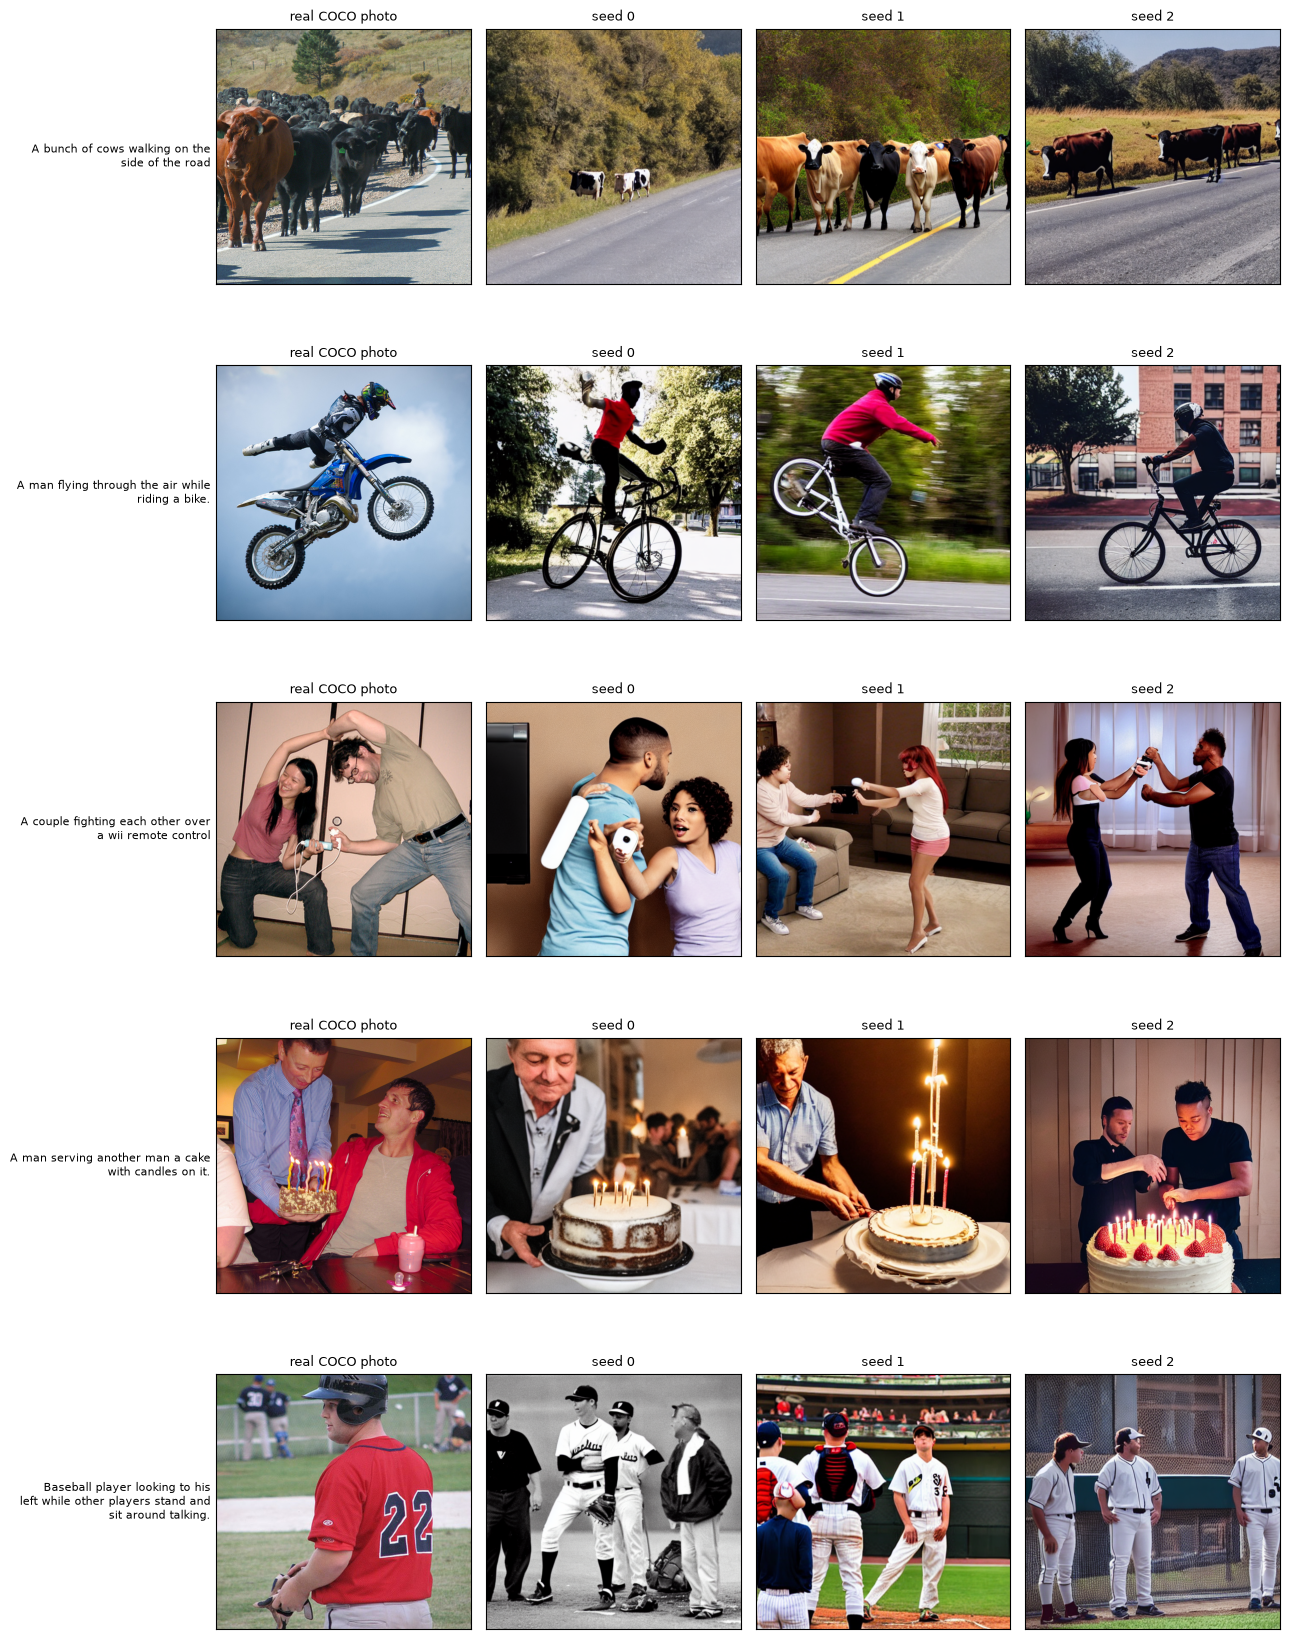

In [7]:
rng = random.Random(7)
pool = df[df.categories.map(len) >= 2]
picked = pool.iloc[sorted(rng.sample(range(len(pool)), 5))]
seeds, rows = [0, 1, 2], []

# one untimed warm-up call so the first timing doesn't include CUDA setup
generate.generate_from_states(pipe, cache["states"][0], cache["null"], seed=999, steps=5)

for _, r in picked.iterrows():
    options = caps.index[caps.image_id == r.image_id].tolist()
    ci = int(rng.choice(options))  # a random one of the image's captions, not always the first
    cap = caps.caption.iloc[ci]
    gens = []
    for s in seeds:
        img, flag, dt = generate.generate_from_states(pipe, cache["states"][ci], cache["null"], seed=s)
        name = f"img{r.image_id}_cap{ci}_seed{s}"
        generate.save_sample(img, OUT / "samples", name,
                             {"image_id": int(r.image_id), "caption_idx": ci, "caption": cap, "seed": s,
                              "steps": 30, "guidance": 7.5, "nsfw_flag": flag,
                              "seconds_end_to_end": round(dt, 2)})
        gens.append((img, flag, dt))
    rows.append((r, cap, gens))

fig, ax = plt.subplots(len(rows), 4, figsize=(13, 3.4 * len(rows)))
for i, (r, cap, gens) in enumerate(rows):
    ax[i, 0].imshow(data.load_image_square(data.IMAGES_DIR / r.file_name))
    ax[i, 0].set_title("real COCO photo", fontsize=9)
    for j, (img, flag, dt) in enumerate(gens):
        ax[i, j + 1].imshow(img)
        ax[i, j + 1].set_title(f"seed {seeds[j]}" + ("  [flagged]" if flag else ""), fontsize=9)
    ax[i, 0].set_ylabel(textwrap.fill(cap, 34), fontsize=8,
                        rotation=0, ha="right", va="center")
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(OUT / "samples_grid.png", dpi=110); plt.show()

## 7. Summary

In [8]:
times = [g[2] for _, _, gens in rows for g in gens]
summary = {
    "images": int(len(df)), "captions": int(len(caps)), "cleaning": log,
    "retrieval": rec,
    "parity": {"token_states_max_abs_diff": diff, "token_states_mean_abs_diff": mean_diff,
               "text_vs_cache_mean_pixel_diff": pix_diff},
    "samples": [{"image_id": int(r.image_id), "caption": cap} for r, cap, _ in rows],
    "seconds_per_image_end_to_end_mean": round(float(np.mean(times)), 2),
    "timing_note": "30 steps, guidance 7.5, includes VAE decode and safety checker, after one warm-up call",
    "flagged": int(sum(g[1] for _, _, gens in rows for g in gens)),
}
json.dump(summary, open(OUT / "summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "images": 5000,
  "captions": 25004,
  "cleaning": {
    "captions_over_token_limit": 0,
    "images_short_side_under_256": 42,
    "captions_whitespace_fixed": 3832,
    "captions_duplicate_dropped": 10,
    "images_not_rgb": 10,
    "images_total": 5000,
    "captions_total": 25004
  },
  "retrieval": {
    "recall@1": 0.35494320908654614,
    "recall@5": 0.5993840985442329,
    "recall@10": 0.7027675571908495,
    "median_rank": 3.0,
    "n_captions": 25004,
    "n_images": 5000,
    "chance_recall@1": 0.0002
  },
  "parity": {
    "token_states_max_abs_diff": 0.0,
    "token_states_mean_abs_diff": 0.0,
    "text_vs_cache_mean_pixel_diff": 0.0
  },
  "samples": [
    {
      "image_id": 87470,
      "caption": "A bunch of cows walking on the side of the road"
    },
    {
      "image_id": 190756,
      "caption": "A man flying through the air while riding a bike."
    },
    {
      "image_id": 234607,
      "caption": "A couple fighting each other over a wii remote control"
  